### 1. Import Required Libraries
We import standard Python libraries for data processing, visualization, and machine learning modeling.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os


### 2. Load Datasets (Train / Val / Test) from Local Storage
Run the cell below to load the preprocessed Train, Validation, and Test CSV files from the `data` directory.

In [2]:
import os
import pandas as pd

# 1. Initialize paths to the 'data' directory
DATA_DIR = os.path.join('.', 'data')

train_path = os.path.join(DATA_DIR, 'smartphones_train_clean.csv')
val_path = os.path.join(DATA_DIR, 'smartphones_val_clean.csv')
test_path = os.path.join(DATA_DIR, 'smartphones_test_clean.csv')

# 2. Load datasets directly from local storage

# Load TRAIN set (Required)
if os.path.exists(train_path):
    df_train = pd.read_csv(train_path)
    print(f"Loaded TRAIN set: {train_path} | Shape: {df_train.shape}")
else:
    raise FileNotFoundError(f"ERROR: Could not find '{train_path}' in '{DATA_DIR}'.")

# Load VALIDATION set (Optional)
if os.path.exists(val_path):
    df_val = pd.read_csv(val_path)
    print(f"Loaded VALIDATION set: {val_path} | Shape: {df_val.shape}")
else:
    df_val = None
    print(f"Skipping VALIDATION set (File not found: '{val_path}').")

# Load TEST set (Optional)
if os.path.exists(test_path):
    df_test = pd.read_csv(test_path)
    print(f"Loaded TEST set: {test_path} | Shape: {df_test.shape}")
else:
    df_test = None
    print(f"Skipping TEST set (File not found: '{test_path}').")

Loaded TRAIN set: .\data\smartphones_train_clean.csv | Shape: (1337, 21)
Loaded VALIDATION set: .\data\smartphones_val_clean.csv | Shape: (286, 21)
Loaded TEST set: .\data\smartphones_test_clean.csv | Shape: (287, 21)


### 3. Preview Training Set Data

In [3]:
pd.set_option('display.max_columns', None)
display(df_train.head())

,Brand,Price (EUR),RAM (GB),ROM (GB),Screen Size (inch),Screen-to-Body Ratio (%),Display Panel,Rear Camera (MP),Front Camera (MP),Battery Capacity (mAh),Battery Design,Thickness (mm),Weight (g),Fingerprint Sensor,Network Support,Chip Brand,CPU Cores,CPU Clock Speed (GHz),Release Year,NFC_Clean,Diagonal Resolution (Pixels)
0,QMobile,400.0,3.0,64.0,6.0,73.5,AMOLED,24.0,8.0,3500.0,Non-removable,9.6,210.0,Available,4G / LTE,MediaTek,8.0,2.00,2015.0,1,2937.209560
1,Panasonic,130.0,2.0,16.0,5.0,67.7,IPS LCD,13.0,5.0,2200.0,Non-removable,8.0,133.0,Available,4G / LTE,Snapdragon,4.0,1.25,2017.0,0,1468.604780
2,Asus,240.0,2.0,32.0,8.0,70.8,IPS LCD,5.0,1.2,2470.0,Non-removable,7.5,299.0,No,4G / LTE,Intel,4.0,2.30,2014.0,1,2264.155472
3,Samsung,410.0,2.0,32.0,5.0,69.2,TFT LCD,13.0,2.0,2600.0,Removable,9.1,147.0,No,4G / LTE,Snapdragon,4.0,2.30,2013.0,1,2202.907170
4,Huawei,200.0,3.0,16.0,5.0,68.8,AMOLED,13.0,5.0,4100.0,Non-removable,7.9,145.0,Available,4G / LTE,MediaTek,8.0,1.40,2016.0,0,1468.604780


### 4. Complete Feature Engineering Pipeline (Domain, Time-Relative & Advanced Features)

In this step, we unify all feature engineering techniques into a consistent pipeline to prevent Data Leakage and ensure alignment across the Train, Validation, and Test sets:
1. **Domain Features:** Compute display sharpness `PPI`, engineering design ratio `Battery_Thickness_Ratio`, total CPU clock speed `Total_CPU_Clock`, composite `Performance_Index`, and `Total_Camera_MP`.
2. **Time-Relative Features (Moore's Law):** Compare a device's RAM, ROM, and Rear Camera against the average of its release year (computed strictly on the Train Set).
3. **Device Age (`Phone_Age`):** Measure the time gap relative to the latest release year in the training dataset.
4. **Advanced Encoding (Target Encoding & One-Hot):** Apply Smoothed Target Encoding ($m=10$) to high-cardinality categorical variables (`Brand`, `Chip Brand`) learned from the Train Set, One-Hot Encoding to low-cardinality categorical variables, and standardize binary indicators.

In [4]:
import pandas as pd
import numpy as np

# --- 1. DEFINE FEATURE ENGINEERING FUNCTIONS ---

def get_column_by_keyword(df, keywords, default=None):
    """Helper function to safely locate a column name by keyword, avoiding IndexError"""
    for c in df.columns:
        if any(k in c for k in keywords):
            return c
    return default

def create_domain_features(df):
    df = df.copy()

    col_screen = get_column_by_keyword(df, ['Screen Size', 'Screen'])
    col_diagonal_res = get_column_by_keyword(df, ['Diagonal Resolution', 'Pixels'])
    col_thickness = get_column_by_keyword(df, ['Thickness'])
    col_battery = get_column_by_keyword(df, ['Battery Capacity', 'Battery'])
    col_cores = get_column_by_keyword(df, ['CPU Cores', 'Cores'])
    col_clock = get_column_by_keyword(df, ['CPU Clock', 'Clock'])
    col_cam_back = get_column_by_keyword(df, ['Rear Camera'])
    col_cam_front = get_column_by_keyword(df, ['Front Camera'])

    # Pixel Density (PPI)
    if col_diagonal_res and col_screen:
        df['PPI'] = df[col_diagonal_res] / (df[col_screen] + 1e-5)
    else:
        df['PPI'] = 0

    # Design & performance indices
    if col_battery and col_thickness:
        df['Battery_Thickness_Ratio'] = df[col_battery] / (df[col_thickness] + 1e-5)

    if col_cores and col_clock:
        df['Total_CPU_Clock'] = df[col_cores] * df[col_clock]
        if 'RAM (GB)' in df.columns:
            df['Performance_Index'] = df['RAM (GB)'] * df['Total_CPU_Clock']

    if col_cam_back and col_cam_front:
        df['Total_Camera_MP'] = df[col_cam_back] + df[col_cam_front]

    return df


def add_time_relative_features(df, stats, global_means_train, col_year, col_cam_back):
    df = df.copy()
    df = df.merge(stats, on=col_year, how='left')

    # Fill NaN for any unseen release years in Val/Test using pure TRAIN global means (Preventing Data Leakage)
    df['mean_ram'] = df['mean_ram'].fillna(global_means_train['ram'])
    df['mean_rom'] = df['mean_rom'].fillna(global_means_train['rom'])
    df['mean_cam'] = df['mean_cam'].fillna(global_means_train['cam'])

    # Compute ratios relative to release year averages
    df['RAM_Rel_Year'] = df['RAM (GB)'] / (df['mean_ram'] + 1e-5)
    df['ROM_Rel_Year'] = df['ROM (GB)'] / (df['mean_rom'] + 1e-5)
    df['Cam_Rel_Year'] = df[col_cam_back] / (df['mean_cam'] + 1e-5)

    return df.drop(columns=['mean_ram', 'mean_rom', 'mean_cam'])


def calculate_smoothed_target_encoding(df, target, column, m=10, global_mean=0.0):
    stats = df.groupby(column)[target].agg(['count', 'sum'])
    smoothed_values = (stats['sum'] + m * global_mean) / (stats['count'] + m)
    return smoothed_values.to_dict()


# --- 2. APPLY SEQUENTIAL TRANSFORMATIONS ---

# Step 2.1: Create preliminary domain features
df_train_feat = create_domain_features(df_train)
df_val_feat = create_domain_features(df_val)
df_test_feat = create_domain_features(df_test)

# Identify key column names
col_year = get_column_by_keyword(df_train, ['Release Year', 'Year'])
col_cam_back = get_column_by_keyword(df_train, ['Rear Camera', 'Rear'])
target_col = get_column_by_keyword(df_train, ['Price'])

y_train = df_train[target_col]
y_val = df_val[target_col]
y_test = df_test[target_col]

# Step 2.2: Compute yearly statistics STRICTLY FROM THE TRAIN SET
year_stats = df_train_feat.groupby(col_year).agg(
    mean_ram=('RAM (GB)', 'mean'),
    mean_rom=('ROM (GB)', 'mean'),
    mean_cam=(col_cam_back, 'mean')
).reset_index()

# Store global means from TRAIN
global_means_train = {
    'ram': df_train_feat['RAM (GB)'].mean(),
    'rom': df_train_feat['ROM (GB)'].mean(),
    'cam': df_train_feat[col_cam_back].mean()
}

# Apply time-relative features across all 3 splits
df_train_final = add_time_relative_features(df_train_feat, year_stats, global_means_train, col_year, col_cam_back)
df_val_final = add_time_relative_features(df_val_feat, year_stats, global_means_train, col_year, col_cam_back)
df_test_final = add_time_relative_features(df_test_feat, year_stats, global_means_train, col_year, col_cam_back)

# Step 2.3: Create advanced encoded features
max_year_train = df_train_final[col_year].max()
global_mean_target = y_train.mean()

# Build Smoothed Target Encoding mappings from the TRAIN set
brand_col = get_column_by_keyword(df_train_final, ['Brand'])
chip_col = get_column_by_keyword(df_train_final, ['Chip Brand', 'Chip'])

brand_te_mapping = calculate_smoothed_target_encoding(df_train_final, target_col, brand_col, m=10, global_mean=global_mean_target) if brand_col else {}
chip_te_mapping = calculate_smoothed_target_encoding(df_train_final, target_col, chip_col, m=10, global_mean=global_mean_target) if chip_col else {}

def build_engineered_features(df):
    df_out = df.copy()

    # Calculate device age & DROP ORIGINAL RELEASE YEAR COLUMN to avoid multicollinearity
    df_out['Phone_Age'] = max_year_train - df_out[col_year]
    df_out = df_out.drop(columns=[col_year], errors='ignore')

    # Apply Smoothed Target Encoding
    if brand_col and brand_col in df_out.columns:
        df_out['Brand_TE'] = df_out[brand_col].map(brand_te_mapping).fillna(global_mean_target)
        df_out = df_out.drop(columns=[brand_col], errors='ignore')

    if chip_col and chip_col in df_out.columns:
        df_out['Chip_Brand_TE'] = df_out[chip_col].map(chip_te_mapping).fillna(global_mean_target)
        df_out = df_out.drop(columns=[chip_col], errors='ignore')

    # One-Hot Encode low-cardinality categorical columns
    low_card_cols = [c for c in ['Battery Design', 'Display Group', 'Display Panel'] if c in df_out.columns]
    if low_card_cols:
        df_out = pd.get_dummies(df_out, columns=low_card_cols, drop_first=True)

    # Binary encode Fingerprint Sensor if object dtype
    fingerprint_col = get_column_by_keyword(df_out, ['Fingerprint'])
    if fingerprint_col and df_out[fingerprint_col].dtype == 'object':
        df_out['Fingerprint_Sensor_Encoded'] = df_out[fingerprint_col].map({'Available': 1, 'No': 0, 'yes': 1, 'no': 0}).fillna(0)
        df_out = df_out.drop(columns=[fingerprint_col])

    # Synchronize NFC column as integer
    nfc_col = get_column_by_keyword(df_out, ['NFC'])
    if nfc_col:
        df_out[nfc_col] = df_out[nfc_col].astype(int)

    # One-Hot Encode any remaining categorical columns
    remaining_cat_cols = df_out.select_dtypes(include=['object', 'category']).columns.tolist()
    if remaining_cat_cols:
        df_out = pd.get_dummies(df_out, columns=remaining_cat_cols, drop_first=True)

    return df_out

# Apply transformation across all 3 splits
df_train_eng = build_engineered_features(df_train_final)
df_val_eng = build_engineered_features(df_val_final)
df_test_eng = build_engineered_features(df_test_final)

# Separate X and y
X_train_eng = df_train_eng.drop(columns=[target_col], errors='ignore')
y_train_eng = df_train_eng[target_col]

X_val_eng = df_val_eng.drop(columns=[target_col], errors='ignore')
y_val_eng = df_val_eng[target_col]

X_test_eng = df_test_eng.drop(columns=[target_col], errors='ignore')
y_test_eng = df_test_eng[target_col]

# Synchronize exact column list and order with X_train_eng using reindex
X_train_eng = X_train_eng.astype(float)
X_val_eng = X_val_eng.reindex(columns=X_train_eng.columns, fill_value=0).astype(float)
X_test_eng = X_test_eng.reindex(columns=X_train_eng.columns, fill_value=0).astype(float)

print("Successfully completed unified Feature Engineering pipeline!")
print(f"Train Set shape: {X_train_eng.shape}")
print(f"Val Set shape:   {X_val_eng.shape}")
print(f"Test Set shape:  {X_test_eng.shape}")

Successfully completed unified Feature Engineering pipeline!
Train Set shape: (1337, 34)
Val Set shape:   (286, 34)
Test Set shape:  (287, 34)


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_22512\4219462437.py:148: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  remaining_cat_cols = df_out.select_dtypes(include=['object', 'category']).columns.tolist()
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_22512\4219462437.py:148: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://

In [5]:
display(X_train_eng.head())

,RAM (GB),ROM (GB),Screen Size (inch),Screen-to-Body Ratio (%),Rear Camera (MP),Front Camera (MP),Battery Capacity (mAh),Thickness (mm),Weight (g),CPU Cores,CPU Clock Speed (GHz),NFC_Clean,Diagonal Resolution (Pixels),PPI,Battery_Thickness_Ratio,Total_CPU_Clock,Performance_Index,Total_Camera_MP,RAM_Rel_Year,ROM_Rel_Year,Cam_Rel_Year,Phone_Age,Brand_TE,Chip_Brand_TE,Battery Design_Removable,Display Panel_IPS LCD,Display Panel_OLED,Display Panel_PLS LCD,Display Panel_Super AMOLED,Display Panel_Super LCD,Display Panel_TFT LCD,Fingerprint Sensor_No,Network Support_3G,Network Support_4G / LTE
0,3.0,64.0,6.0,73.5,24.0,8.0,3500.0,9.6,210.0,8.0,2.00,1.0,2937.209560,489.534111,364.582954,16.0,48.0,32.0,1.612013,2.970420,2.182691,2.0,177.026926,189.263601,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2.0,16.0,5.0,67.7,13.0,5.0,2200.0,8.0,133.0,4.0,1.25,0.0,1468.604780,293.720369,274.999656,5.0,10.0,18.0,0.633389,0.375510,1.007581,0.0,193.225131,246.753508,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2.0,32.0,8.0,70.8,5.0,1.2,2470.0,7.5,299.0,4.0,2.30,1.0,2264.155472,283.019080,329.332894,9.2,18.4,6.2,1.368182,2.143343,0.526916,3.0,275.871462,213.455497,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,2.0,32.0,5.0,69.2,13.0,2.0,2600.0,9.1,147.0,4.0,2.30,1.0,2202.907170,440.580553,285.713972,9.2,18.4,15.0,1.443928,2.121901,1.565406,4.0,277.710522,246.753508,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0
4,3.0,16.0,5.0,68.8,13.0,5.0,4100.0,7.9,145.0,8.0,1.40,0.0,1468.604780,293.720369,518.986685,11.2,33.6,18.0,1.123539,0.435411,1.062826,1.0,256.032277,189.263601,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


### 5. Train Baseline Random Forest and XGBoost on Engineered Features (Before Hyperparameter Tuning)

In [6]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate_model(y_true, y_pred, model_name="Model"):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"--- {model_name} ---")
    print(f"MAE : {mae:.2f} EUR")
    print(f"RMSE: {rmse:.2f} EUR")
    print(f"R2  : {r2:.4f}\n")

# 1. Random Forest Baseline
rf_baseline = RandomForestRegressor(random_state=42)
rf_baseline.fit(X_train_eng, y_train_eng)

print("=== EVALUATION ON VALIDATION SET ===")
evaluate_model(y_val_eng, rf_baseline.predict(X_val_eng), "Random Forest (Baseline)")

# 2. XGBoost Baseline
xgb_baseline = XGBRegressor(random_state=42, n_estimators=100, learning_rate=0.1)
xgb_baseline.fit(X_train_eng, y_train_eng)

evaluate_model(y_val_eng, xgb_baseline.predict(X_val_eng), "XGBoost (Baseline)")

=== EVALUATION ON VALIDATION SET ===
--- Random Forest (Baseline) ---
MAE : 50.62 EUR
RMSE: 73.46 EUR
R2  : 0.7208

--- XGBoost (Baseline) ---
MAE : 48.26 EUR
RMSE: 66.90 EUR
R2  : 0.7685



In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importances from the XGBoost Baseline model
importances = pd.Series(xgb_baseline.feature_importances_, index=X_train_eng.columns)
top_features = importances.sort_values(ascending=False).head(15)

print("Top 15 most important features:")
print(top_features)

Top 15 most important features:
Diagonal Resolution (Pixels)    0.365615
CPU Clock Speed (GHz)           0.158810
ROM (GB)                        0.081832
Cam_Rel_Year                    0.051153
NFC_Clean                       0.043360
Fingerprint Sensor_No           0.040849
RAM_Rel_Year                    0.028175
PPI                             0.021832
Brand_TE                        0.019716
Performance_Index               0.015309
ROM_Rel_Year                    0.013960
Total_CPU_Clock                 0.013442
Display Panel_IPS LCD           0.011461
Total_Camera_MP                 0.011178
Display Panel_Super AMOLED      0.010853
dtype: float32


### 6. Feature Selection Based on Feature Importance and Model Re-evaluation

We filter out features contributing less than 0.5% to the XGBoost model, then retrain and evaluate both **Random Forest** and **XGBoost** on this compact 28-feature subset.

In [8]:
# 1. Select importance threshold (keep features contributing > 0.5% to the model)
threshold = 0.005
selected_features = importances[importances > threshold].index.tolist()

print(f"Initial number of features: {X_train_eng.shape[1]}")
print(f"Number of features retained after filtering: {len(selected_features)}")
print("Retained features:", selected_features)

# 2. Create subset datasets containing only the selected features
X_train_sub = X_train_eng[selected_features]
X_val_sub = X_val_eng[selected_features]
X_test_sub = X_test_eng[selected_features]

Initial number of features: 34
Number of features retained after filtering: 28
Retained features: ['ROM (GB)', 'Screen-to-Body Ratio (%)', 'Rear Camera (MP)', 'Front Camera (MP)', 'Battery Capacity (mAh)', 'Thickness (mm)', 'Weight (g)', 'CPU Cores', 'CPU Clock Speed (GHz)', 'NFC_Clean', 'Diagonal Resolution (Pixels)', 'PPI', 'Battery_Thickness_Ratio', 'Total_CPU_Clock', 'Performance_Index', 'Total_Camera_MP', 'RAM_Rel_Year', 'ROM_Rel_Year', 'Cam_Rel_Year', 'Phone_Age', 'Brand_TE', 'Chip_Brand_TE', 'Battery Design_Removable', 'Display Panel_IPS LCD', 'Display Panel_Super AMOLED', 'Display Panel_Super LCD', 'Fingerprint Sensor_No', 'Network Support_3G']


In [9]:
# 3. Retrain Random Forest on the filtered feature subset
rf_sub = RandomForestRegressor(random_state=42)
rf_sub.fit(X_train_sub, y_train_eng)

# 4. Retrain XGBoost on the filtered feature subset
xgb_sub = XGBRegressor(random_state=42, n_estimators=100, learning_rate=0.1)
xgb_sub.fit(X_train_sub, y_train_eng)

# 5. Evaluate and directly compare results
print("=== EVALUATION RESULTS AFTER FEATURE FILTERING (ON VALIDATION SET) ===\n")
evaluate_model(y_val_eng, rf_sub.predict(X_val_sub), "Random Forest (Filtered)")
evaluate_model(y_val_eng, xgb_sub.predict(X_val_sub), "XGBoost (Filtered)")

=== EVALUATION RESULTS AFTER FEATURE FILTERING (ON VALIDATION SET) ===

--- Random Forest (Filtered) ---
MAE : 50.31 EUR
RMSE: 72.67 EUR
R2  : 0.7268

--- XGBoost (Filtered) ---
MAE : 48.57 EUR
RMSE: 67.57 EUR
R2  : 0.7639



### 7. Confirm Official Training Feature Configuration

Because threshold-based feature pruning slightly reduces XGBoost performance on the Validation Set, we **retain all 34 engineered features** from the Feature Engineering pipeline for downstream hyperparameter tuning.

* Official datasets: `X_train_eng`, `X_val_eng`, `X_test_eng`

In [10]:
# Confirm final feature matrices used from this point onward
X_train_final = X_train_eng
X_val_final = X_val_eng
X_test_final = X_test_eng

print("Confirmed full 34-feature dataset for tuning:")
print(f"- Train: {X_train_final.shape}")
print(f"- Val:   {X_val_final.shape}")
print(f"- Test:  {X_test_final.shape}")

Confirmed full 34-feature dataset for tuning:
- Train: (1337, 34)
- Val:   (286, 34)
- Test:  (287, 34)


In [11]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Hyperparameter search space for Random Forest
param_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [6, 10, 15],
    'min_samples_split': [2, 5, 10]
}

# 2. Randomized search on the full 34-feature dataset
rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_rf,
    n_iter=10,
    scoring='neg_mean_absolute_error',
    cv=5,
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train_final, y_train_eng)
best_rf = rf_search.best_estimator_

print("=== OPTIMAL RANDOM FOREST HYPERPARAMETERS ===")
print(rf_search.best_params_)

# 3. Helper function to print evaluation metrics
def print_evaluation_metrics(y_true, y_pred, set_name="Dataset"):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"\n--- Evaluation on {set_name} ---")
    print(f"  MAE  (Mean Absolute Error)      : {mae:.2f} EUR")
    print(f"  RMSE (Root Mean Squared Error)  : {rmse:.2f} EUR")
    print(f"  R2   (Coefficient of Determination): {r2:.4f}")

# 4. Print evaluation metrics across all splits
print("\n=== RANDOM FOREST MODEL EVALUATION RESULTS ===")
print_evaluation_metrics(y_train_eng, best_rf.predict(X_train_final), "TRAIN Set")

if 'X_val_final' in locals() and 'y_val_eng' in locals():
    print_evaluation_metrics(y_val_eng, best_rf.predict(X_val_final), "VALIDATION Set")

if 'X_test_final' in locals() and 'y_test_eng' in locals():
    print_evaluation_metrics(y_test_eng, best_rf.predict(X_test_final), "TEST Set")

=== OPTIMAL RANDOM FOREST HYPERPARAMETERS ===
{'n_estimators': 100, 'min_samples_split': 5, 'max_depth': 15}

=== RANDOM FOREST MODEL EVALUATION RESULTS ===

--- Evaluation on TRAIN Set ---
  MAE  (Mean Absolute Error)      : 22.47 EUR
  RMSE (Root Mean Squared Error)  : 34.96 EUR
  R2   (Coefficient of Determination): 0.9348

--- Evaluation on VALIDATION Set ---
  MAE  (Mean Absolute Error)      : 50.42 EUR
  RMSE (Root Mean Squared Error)  : 72.86 EUR
  R2   (Coefficient of Determination): 0.7254

--- Evaluation on TEST Set ---
  MAE  (Mean Absolute Error)      : 48.40 EUR
  RMSE (Root Mean Squared Error)  : 69.42 EUR
  R2   (Coefficient of Determination): 0.7273


In [12]:
import numpy as np
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Hyperparameter search space for XGBoost
param_xgb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.7, 0.8, 0.9]
}

# 2. Randomized search on the full 34-feature dataset
xgb_search = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_xgb,
    n_iter=10,
    scoring='neg_mean_absolute_error',
    cv=5,
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train_final, y_train_eng)
best_xgb = xgb_search.best_estimator_

print("=== OPTIMAL XGBOOST HYPERPARAMETERS ===")
print(xgb_search.best_params_)

# 3. Print evaluation metrics across all splits
print("\n=== XGBOOST MODEL EVALUATION RESULTS ===")
print_evaluation_metrics(y_train_eng, best_xgb.predict(X_train_final), "TRAIN Set")

if 'X_val_final' in locals() and 'y_val_eng' in locals():
    print_evaluation_metrics(y_val_eng, best_xgb.predict(X_val_final), "VALIDATION Set")

if 'X_test_final' in locals() and 'y_test_eng' in locals():
    print_evaluation_metrics(y_test_eng, best_xgb.predict(X_test_final), "TEST Set")

=== OPTIMAL XGBOOST HYPERPARAMETERS ===
{'subsample': 0.9, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05}

=== XGBOOST MODEL EVALUATION RESULTS ===

--- Evaluation on TRAIN Set ---
  MAE  (Mean Absolute Error)      : 18.69 EUR
  RMSE (Root Mean Squared Error)  : 25.10 EUR
  R2   (Coefficient of Determination): 0.9664

--- Evaluation on VALIDATION Set ---
  MAE  (Mean Absolute Error)      : 46.19 EUR
  RMSE (Root Mean Squared Error)  : 64.78 EUR
  R2   (Coefficient of Determination): 0.7829

--- Evaluation on TEST Set ---
  MAE  (Mean Absolute Error)      : 46.45 EUR
  RMSE (Root Mean Squared Error)  : 66.81 EUR
  R2   (Coefficient of Determination): 0.7474


In [13]:
# Weighted blending predictions on the Test Set using the full 34-feature set X_test_final
y_pred_rf = best_rf.predict(X_test_final)
y_pred_xgb = best_xgb.predict(X_test_final)

# Blend predictions: 70% XGBoost + 30% Random Forest
y_pred_ensemble = 0.7 * y_pred_xgb + 0.3 * y_pred_rf

print("=== ENSEMBLE MODEL RESULTS (BLENDING) ===")
print_evaluation_metrics(y_test_eng, y_pred_ensemble, "TEST Set (Ensemble)")

=== ENSEMBLE MODEL RESULTS (BLENDING) ===

--- Evaluation on TEST Set (Ensemble) ---
  MAE  (Mean Absolute Error)      : 46.52 EUR
  RMSE (Root Mean Squared Error)  : 66.82 EUR
  R2   (Coefficient of Determination): 0.7473


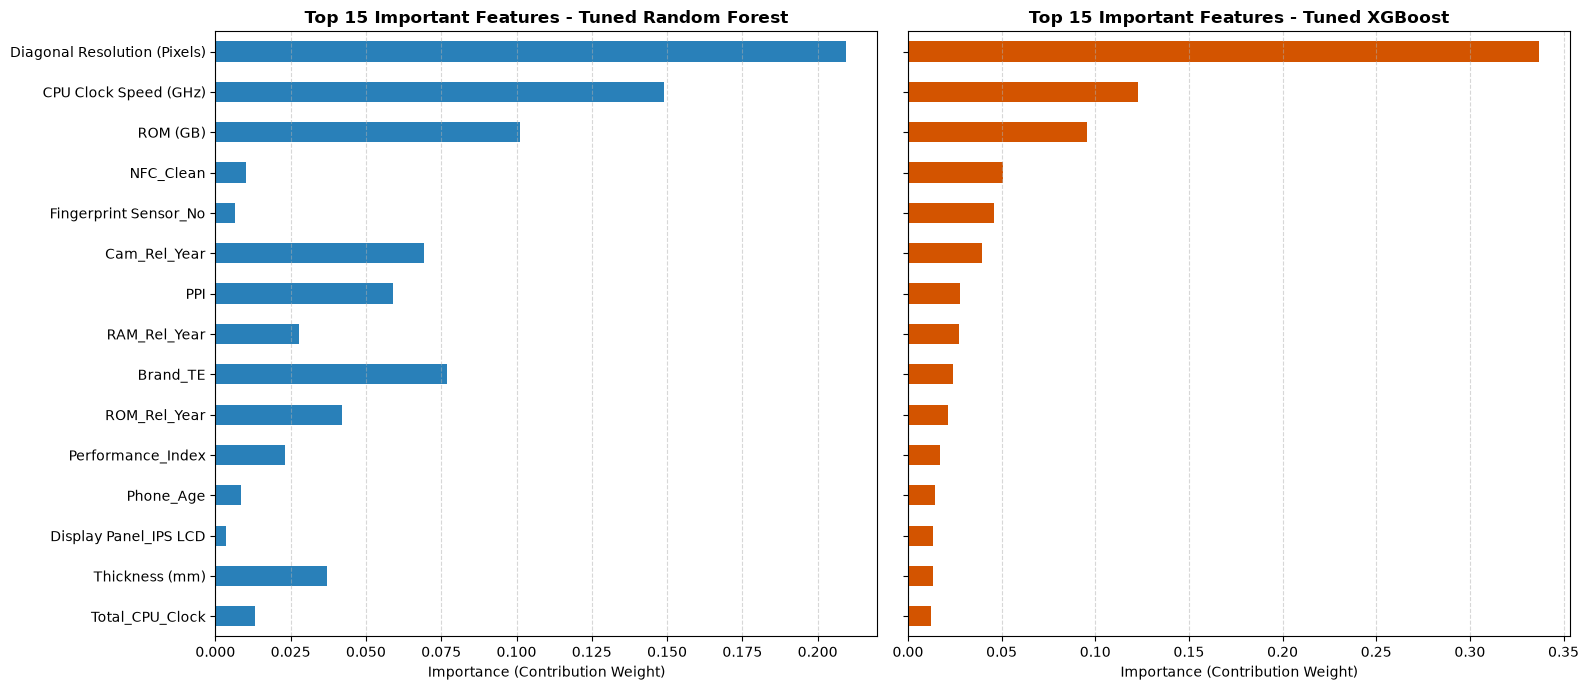

=== TOP 10 MOST IMPORTANT FEATURES (TUNED XGBOOST) ===


,Feature,Random Forest,XGBoost
0,Diagonal Resolution (Pixels),0.209392,0.336658
1,CPU Clock Speed (GHz),0.148951,0.122997
2,ROM (GB),0.101196,0.095799
3,NFC_Clean,0.010010,0.050925
4,Fingerprint Sensor_No,0.006410,0.045910
5,Cam_Rel_Year,0.069374,0.039632
6,PPI,0.058934,0.027762
7,RAM_Rel_Year,0.027711,0.027373
8,Brand_TE,0.076845,0.023845
9,ROM_Rel_Year,0.042030,0.021363


In [14]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Automatically retrieve the exact feature names learned by the models
feature_cols = getattr(
    best_rf,
    'feature_names_in_',
    X_train_final.columns if 'X_train_final' in locals() else X_train_eng.columns,
)

# 2. Extract Feature Importances from the two tuned models
rf_final_imp = pd.Series(best_rf.feature_importances_, index=feature_cols)
xgb_final_imp = pd.Series(best_xgb.feature_importances_, index=feature_cols)

df_final_imp = pd.DataFrame(
    {'Random Forest': rf_final_imp, 'XGBoost': xgb_final_imp}
)

# 3. Select Top 15 most important features (ranked by XGBoost importance) for clear visualization
top_15 = df_final_imp.sort_values(by='XGBoost', ascending=True).tail(15)

# 4. Plot side-by-side comparison bar charts
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

top_15['Random Forest'].plot(kind='barh', ax=axes[0], color='#2980b9')
axes[0].set_title(
    'Top 15 Important Features - Tuned Random Forest',
    fontsize=12,
    fontweight='bold',
)
axes[0].set_xlabel('Importance (Contribution Weight)')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

top_15['XGBoost'].plot(kind='barh', ax=axes[1], color='#d35400')
axes[1].set_title(
    'Top 15 Important Features - Tuned XGBoost',
    fontsize=12,
    fontweight='bold',
)
axes[1].set_xlabel('Importance (Contribution Weight)')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Display Top 10 most important features table
print('=== TOP 10 MOST IMPORTANT FEATURES (TUNED XGBOOST) ===')
display(
    df_final_imp.sort_values(by='XGBoost', ascending=False)
    .head(10)
    .reset_index()
    .rename(columns={'index': 'Feature'})
)